# Testbed Visualizations

Two figures for the TCC baseline write-up:

1. **Bandwidth profiles** — the `tc htb` cap schedule of all 7 testbed scenarios.
2. **RTT response** — how round-trip time reacts to congestion in one baseline run (scenario B).

Run the cells top-to-bottom. Each figure is also saved as a PNG next to this notebook.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DURATION = 240          # s — length of a campaign scenario
FREE = 24               # Mbps — plotting level for the unshaped (uncapped) state
TARGET = 19             # Mbps — negotiated encoder target (~18988 kbps)

BASELINE_DIR = Path('../results/baseline')

## 1. Bandwidth profiles

Each scenario degrades the network by capping bandwidth with `tc htb`. The encoder
target is ~19 Mbps (negotiated from a 25 Mbps client slider). When a cap drops below
the encoder's real output, the bottleneck queue fills — that is the congestion the
adaptive controller (PR #2) must handle.

The schedules below mirror `testbed/lib/scenarios.sh`. Each entry is `(time_s, cap_Mbps)`;
the cap holds until the next entry. `FREE` marks the unshaped state.

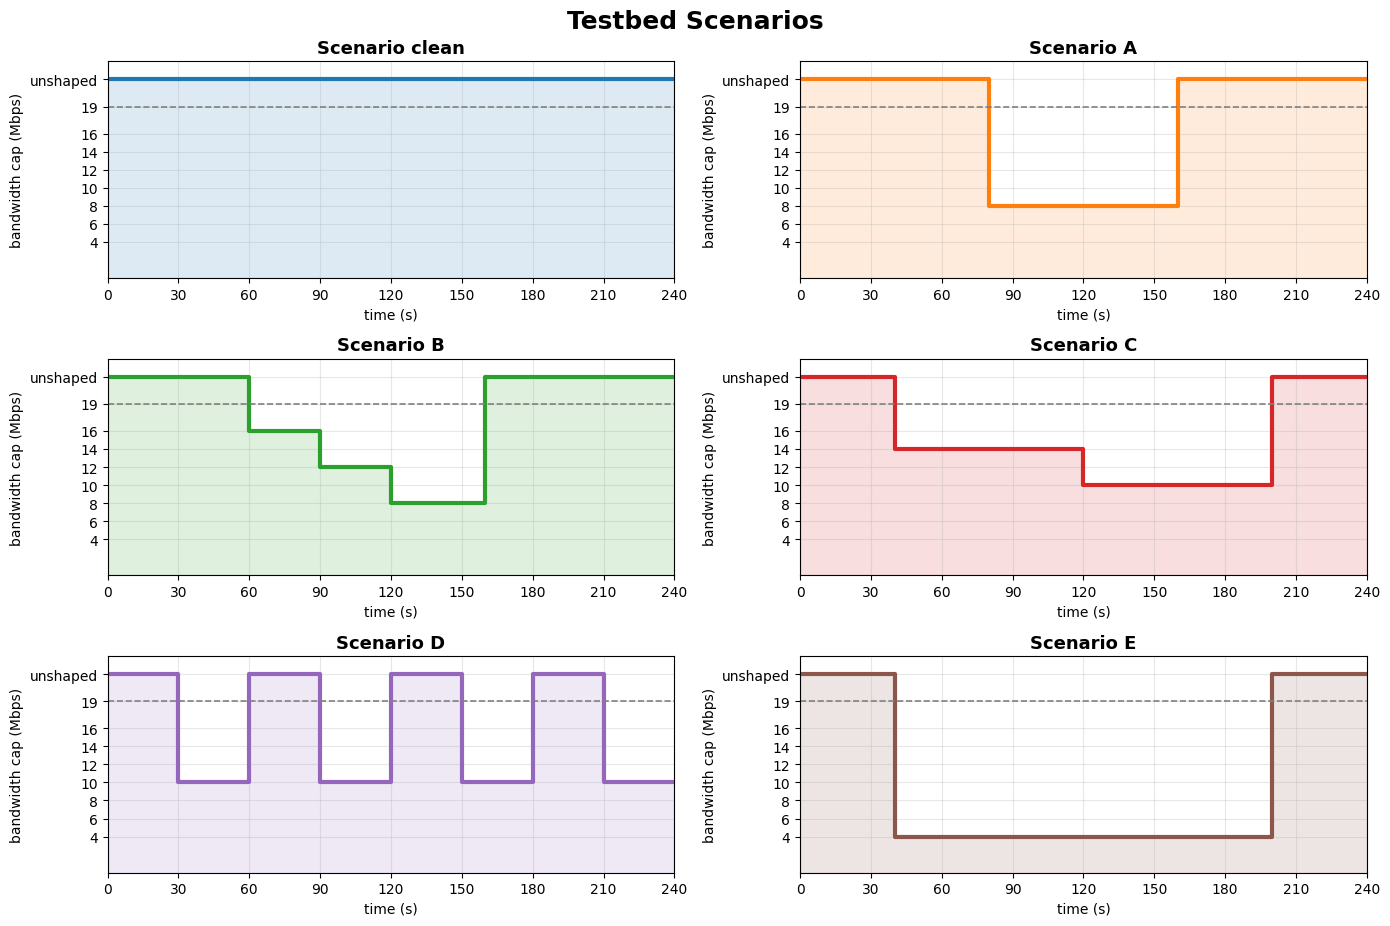

In [2]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

FREE = 22          # valor usado para representar "unshaped"
TARGET = 19
DURATION = 240

# (time_s, cap_Mbps)
SCENARIOS = {
    'clean': [(0, FREE)],
    'A':     [(0, FREE), (80, 8), (160, FREE)],
    'B':     [(0, FREE), (60, 16), (90, 12), (120, 8), (160, FREE)],
    'C':     [(0, FREE), (40, 14), (120, 10), (200, FREE)],
    'D':     [(0, FREE), (30, 10), (60, FREE), (90, 10), (120, FREE),
              (150, 10), (180, FREE), (210, 10)],
    'E':     [(0, FREE), (40, 4), (200, FREE)],
    'F':     [(0, 6), (160, FREE)],
}


def step_xy(schedule, duration=DURATION):
    xs = [t for t, _ in schedule] + [duration]
    ys = [cap for _, cap in schedule] + [schedule[-1][1]]
    return xs, ys


# =========================
# VISUALIZAÇÕES SEPARADAS
# =========================

fig = plt.figure(figsize=(14, 12))
gs = GridSpec(4, 2, figure=fig)

colors = plt.cm.tab10.colors

scenario_names = list(SCENARIOS.keys())

for idx, name in enumerate(scenario_names):

    row = idx // 2
    col = idx % 2

    ax = fig.add_subplot(gs[row, col])

    sched = SCENARIOS[name]
    xs, ys = step_xy(sched)

    ax.step(
        xs,
        ys,
        where='post',
        linewidth=3,
        color=colors[idx]
    )

    # área preenchida
    ax.fill_between(
        xs,
        ys,
        step='post',
        alpha=0.15,
        color=colors[idx]
    )

    # linha do target
    ax.axhline(
        TARGET,
        linestyle='--',
        linewidth=1.2,
        color='gray'
    )

    ax.set_title(
        f'Scenario {name}',
        fontsize=13,
        fontweight='bold'
    )

    ax.set_xlim(0, DURATION)
    ax.set_ylim(0, FREE + 2)

    ax.set_xticks(range(0, 241, 30))
    ax.set_yticks([4, 6, 8, 10, 12, 14, 16, 19, FREE])

    ax.set_yticklabels([
        '4', '6', '8', '10',
        '12', '14', '16',
        '19', 'unshaped'
    ])

    ax.grid(alpha=0.3)

    ax.set_xlabel('time (s)')
    ax.set_ylabel('bandwidth cap (Mbps)')


# remove subplot vazio
fig.delaxes(fig.axes[-1])

fig.suptitle(
    'Testbed Scenarios',
    fontsize=18,
    fontweight='bold'
)

plt.tight_layout()
plt.savefig('scenario_bandwidth_profiles_separate.png', dpi=150)
plt.show()

## 2. RTT response in a baseline run

### What is RTT, and why is it the signal we want?

**RTT (Round-Trip Time)** is the time for a packet to travel server → client and for
its acknowledgment to return, in milliseconds. Sunshine gets it for free from the
ENet transport layer (`peer->roundTripTime`).

It is a strong congestion signal because:

- **Server-side, no clock sync.** Measured entirely on the host (send time → ack
  time). Unlike one-way delay, it needs no synchronized clocks.
- **Early.** When a link saturates, packets first *queue* (bufferbloat) before any
  are dropped. Queue time inflates RTT, so RTT rises *before* quality collapses — a
  controller can react ahead of visible damage.
- **Proportional.** RTT reports *how bad* congestion is, not just on/off — see the
  step ramp below.
- **Cheap.** ENet already computes it; no extra probe traffic.

*Caveat:* after the network recovers, the queue still has to drain, so RTT stays
high for a while (bufferbloat lag). A controller must expect that.

### Why scenario B

B steps the cap down 16 → 12 → 8 Mbps. RTT climbs in matching steps, which shows the
*proportional* property far better than a single on/off cap would.

*Note:* the CSV's `elapsed_ms` is measured from session start; the session/scenario
offset is small (~0-5 s) for these campaign runs, so CSV time is treated as scenario
time here.

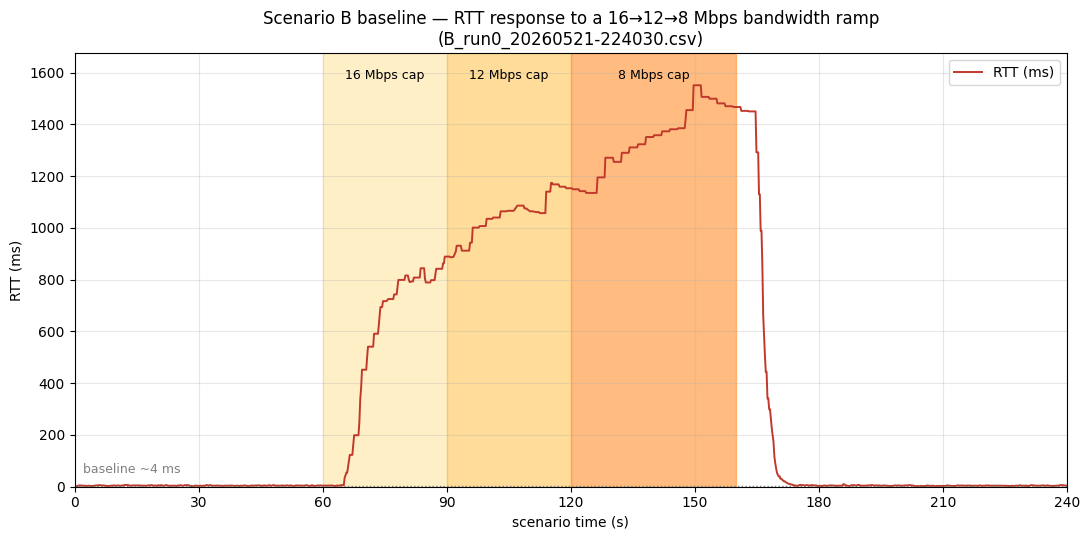

In [3]:
csv = sorted(BASELINE_DIR.glob('B_run0_*.csv'))[-1]
df = pd.read_csv(csv)
df['t'] = df['elapsed_ms'] / 1000.0

# B cap phases (scenario seconds): (start, end, cap_Mbps)
B_PHASES = [(60, 90, 16), (90, 120, 12), (120, 160, 8)]
SHADE = {16: '#ffe9b0', 12: '#ffce6e', 8: '#ff9f4a'}

baseline_rtt = df.loc[df['t'] < 55, 'rtt_ms'].mean()

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(df['t'], df['rtt_ms'], color='#c0392b', lw=1.4, label='RTT (ms)')

y_top = df['rtt_ms'].max() * 1.08
for t0, t1, cap in B_PHASES:
    ax.axvspan(t0, t1, color=SHADE[cap], alpha=0.7, zorder=0)
    ax.text((t0 + t1) / 2, y_top * 0.94, f'{cap} Mbps cap',
            ha='center', fontsize=9)

ax.axhline(baseline_rtt, ls=':', color='gray', lw=1)
ax.text(2, baseline_rtt + y_top * 0.03,
        f'baseline ~{baseline_rtt:.0f} ms', color='gray', fontsize=9)

ax.set_xlim(0, 240)
ax.set_ylim(0, y_top)
ax.set_xticks(range(0, 241, 30))
ax.set_xlabel('scenario time (s)')
ax.set_ylabel('RTT (ms)')
ax.set_title('Scenario B baseline — RTT response to a 16→12→8 Mbps bandwidth ramp\n'
             f'({csv.name})')
ax.grid(alpha=0.3)
ax.legend(loc='upper right')

plt.tight_layout()
plt.savefig('scenario_B_rtt.png', dpi=130)
plt.show()